In [ ]:
import requests
import pandas as pd

# 1) Endereço da API (endpoint)
url = "https://api.open-meteo.com/v1/forecast"

# 2) As 10 variáveis que queremos
variaveis = [
    "temperature_2m",             # temperatura do ar (°C)
    "apparent_temperature",       # sensação térmica (°C)
    "relative_humidity_2m",       # umidade relativa (%)
    "precipitation",              # chuva acumulada na hora (mm)
    "precipitation_probability",  # probabilidade de chuva (%)
    "cloud_cover",                # cobertura de nuvens (%)
    "wind_speed_10m",             # velocidade do vento (km/h)
    "wind_direction_10m",         # direção do vento (°)
    "pressure_msl",               # pressão ao nível do mar (hPa)
    "uv_index",                   # índice UV
]

# 3) Parâmetros da requisição: local, variáveis e fuso horário
params = {
    "latitude": -23.55,           # São Paulo
    "longitude": -46.63,
    "hourly": ",".join(variaveis),
    "timezone": "America/Sao_Paulo",
}

# 4) Chamada à API
resp = requests.get(url.format(codigo=), params=params, timeout=10)
resp.raise_for_status()           # para o programa se a API retornar erro
dados = resp.json()               # converte a resposta JSON em dicionário Python

# 5) Transformar em DataFrame
df = pd.DataFrame(dados["hourly"])
df["time"] = pd.to_datetime(df["time"])

# 6) (Opcional) Renomear as colunas para português
df = df.rename(columns={
    "time": "data_hora",
    "temperature_2m": "temperatura",
    "apparent_temperature": "sensacao_termica",
    "relative_humidity_2m": "umidade",
    "precipitation": "chuva_mm",
    "precipitation_probability": "prob_chuva",
    "cloud_cover": "nuvens",
    "wind_speed_10m": "vento_kmh",
    "wind_direction_10m": "vento_direcao",
    "pressure_msl": "pressao",
    "uv_index": "indice_uv",
})

df

,data_hora,temperatura,sensacao_termica,umidade,chuva_mm,prob_chuva,nuvens,vento_kmh,vento_direcao,pressao,indice_uv
0,2026-09-28 00:00:00,18.5,19.6,86,0.0,0,100,7.2,108,1018.8,0.0
1,2026-09-28 01:00:00,18.5,19.3,87,0.0,0,100,8.6,74,1017.4,0.0
2,2026-09-28 02:00:00,18.0,18.9,89,0.0,0,100,8.6,74,1016.5,0.0
3,2026-09-28 03:00:00,18.2,19.1,89,0.0,0,100,8.6,113,1017.5,0.0
4,2026-09-28 04:00:00,17.9,19.1,92,0.0,0,100,7.3,100,1016.4,0.0
...,...,...,...,...,...,...,...,...,...,...,...
163,2026-10-04 19:00:00,20.2,22.2,91,0.2,88,97,8.2,351,1013.5,0.0
164,2026-10-04 20:00:00,20.3,22.0,89,0.2,85,96,9.4,348,1013.9,0.0
165,2026-10-04 21:00:00,20.3,21.9,88,0.2,80,95,10.0,345,1014.1,0.0
166,2026-10-04 22:00:00,20.2,21.6,88,0.0,73,95,10.1,343,1014.1,0.0


In [ ]:
colunas = ["temperatura", "sensacao_termica", "umidade", "chuva_mm"]

for i in colunas:
    print(f'Coluna: {i}')
    print(f'Min: {df[i].min()}')
    print(f'Max: {df[i].max()}')
    print(f'Média: {df[i].mean()}')
    print(f'Mediana: {df[i].mean()}')

Coluna: temperatura
Min: 12.8
Max: 34.1
Média: 22.342857142857145
Mediana: 22.342857142857145
Coluna: sensacao_termica
Min: 12.0
Max: 34.9
Média: 24.049999999999997
Mediana: 24.049999999999997
Coluna: umidade
Min: 29
Max: 100
Média: 74.17857142857143
Mediana: 74.17857142857143
Coluna: chuva_mm
Min: 0.0
Max: 0.6
Média: 0.050595238095238096
Mediana: 0.050595238095238096


In [ ]:
# Funções em python

1. Usando lambda
2. Usando apply
3. Usando função agg()

In [ ]:
Exercícios

1. Crie uma estrutura para calcular/retornar os valores min, max, media e mediana das colunas "temperatura", "sensacao_termica", "umidade", "chuva_mm".config/

a. Utilize uma estrutura com repetição.
b. Utilize uma estrutura com pandas.
c. Utilize uma estrutura com lambda.

2. Crie um gráfico para mostrar as curvas de 'temperatura' e 'sensacao_termica'.

3. O que acontece com o gráfico ao incluir a variável pressao no mesmo gráfico?

4. O que fazer para resolver o problema da questão 3?







Index(['data_hora', 'temperatura', 'sensacao_termica', 'umidade', 'chuva_mm',
       'prob_chuva', 'nuvens', 'vento_kmh', 'vento_direcao', 'pressao',
       'indice_uv'],
      dtype='object')

In [ ]:
# Abordage 1
colunas = ["temperatura", "sensacao_termica", "umidade", "chuva_mm"]

for coluna in colunas:
  print(f'Coluna: {coluna}')
  print(f'Min: {df[coluna].min()}')
  print(f'Max: {df[coluna].max()}')
  print(f'Media: {df[coluna].mean()}')
  print(f'Mediana: {df[coluna].median()}')

Coluna: temperatura
Min: 12.8
Max: 34.1
Media: 22.342857142857145
Mediana: 21.2
Coluna: sensacao_termica
Min: 12.0
Max: 34.9
Media: 24.049999999999997
Mediana: 23.6
Coluna: umidade
Min: 29
Max: 100
Media: 74.17857142857143
Mediana: 81.0
Coluna: chuva_mm
Min: 0.0
Max: 0.6
Media: 0.050595238095238096
Mediana: 0.0


In [ ]:
# Abordagem 2

# Coluna temperatura
df["temperatura"].min()
df["temperatura"].max()
df["temperatura"].mean()
df["temperatura"].median()

# Coluna sensação térmica
df["sensacao_termica"].min()
df["sensacao_termica"].max()
df["sensacao_termica"].mean()
df["sensacao_termica"].median()

# Coluna umidade
df["umidade"].min()
df["umidade"].max()
df["umidade"].mean()
df["umidade"].median()

# Coluna chuva_mm
df["chuva_mm"].min()
df["chuva_mm"].max()
df["chuva_mm"].mean()
df["chuva_mm"].median()

##################################################

0.0

In [ ]:
# Abordagem 3 - Usando Lambda
colunas = ["temperatura", "sensacao_termica", "umidade", "chuva_mm"]

# Funções utilizadas
funcoes = {
    'min': lambda x: x.min(),
    'max': lambda x: x.max(),
    'mean': lambda x: x.mean(),
    'median': lambda x: x.median()
    }

for coluna in colunas:
  print(f'Coluna: {coluna}')
  for nome_funcao, funcao in funcoes.items():
    resultado = funcao(df[coluna])
    print(f'{nome_funcao}: {resultado}')

Coluna: temperatura
min: 13.4
max: 34.9
mean: 22.60238095238095
median: 21.25
Coluna: sensacao_termica
min: 12.8
max: 35.2
mean: 24.310119047619047
median: 23.65
Coluna: umidade
min: 26
max: 100
mean: 74.08333333333333
median: 82.0
Coluna: chuva_mm
min: 0.0
max: 0.6
mean: 0.07380952380952382
median: 0.0


In [ ]:
# Abordagem 4 - Utilizando a função agg() em python

colunas = ["temperatura", "sensacao_termica", "umidade", "chuva_mm"]
df[colunas].agg(["min", "max", "mean", "median"])

,temperatura,sensacao_termica,umidade,chuva_mm
min,13.400000,12.800000,26.000000,0.00000
max,34.900000,35.200000,100.000000,0.60000
mean,22.602381,24.310119,74.083333,0.07381
median,21.250000,23.650000,82.000000,0.00000


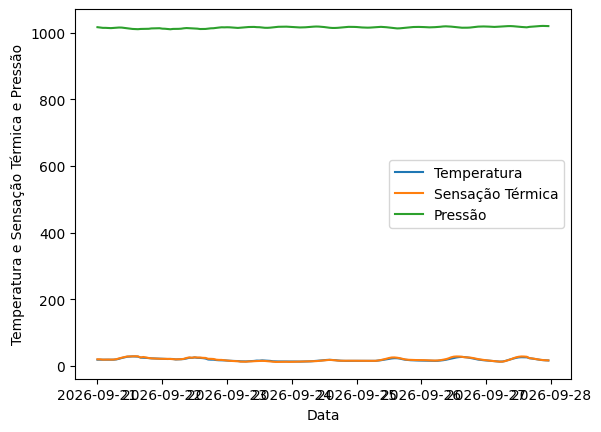

In [ ]:
# Plote temperatura e sensacao_térmica
import matplotlib.pyplot as plt

x = df['data_hora']
y1 = df['temperatura']
y2 = df['sensacao_termica']
y3 = df['pressao']

plt.plot(x, y1, x, y2, x, y3)
plt.xlabel("Data")
plt.ylabel("Temperatura e Sensação Térmica e Pressão")
plt.legend(['Temperatura', 'Sensação Térmica', 'Pressão'])
plt.show()

In [ ]:
# Recurso com recursão
def fib(n):
  if n <= 1:
    return n
  return fib(n-1) + fib(n-2)

%time fib(40)

CPU times: user 25.1 s, sys: 5.6 ms, total: 25.1 s
Wall time: 25.8 s


102334155

In [ ]:
# Recurso com recursão e memoização
def fib_memo(n, memo={}):
  if n in memo:
    return memo[n]
  if n <= 1:
    return n
  memo[n] = fib_memo(n-1, memo) + fib_memo(n-2, memo)
  return memo[n]

%time fib_memo(40)

CPU times: user 30 µs, sys: 1 µs, total: 31 µs
Wall time: 34.6 µs


102334155